# COMP6200 - Critical Analysis

## Task 2: Code Repair

In [1]:
import pandas
import math

In [3]:
df = pandas.read_csv('company_directorships.csv')
df.software_background = df.software_background.map(lambda x: x == 't')
df.sample(5)

,company_name,cikcode,director_name,software_background,start_date,end_date
2813,"ConnectOne Bancorp, Inc.",712771,JOSEPH PARISI JR.,False,2015-04-15,2019-04-22
1967,CARPENTER TECHNOLOGY CORP,17843,ANDREW T. ZIOLKOWSKI,False,2015-09-15,2015-09-15
11774,TIDEWATER INC,98222,RICHARD T. DU MOULIN,False,2014-06-27,2016-06-10
5217,"GERMAN AMERICAN BANCORP, INC.",714395,MARK A. SCHROEDER,False,2019-04-01,2022-03-29
11418,TEAM INC,318833,GRANT D. ROSCOE,False,2019-04-11,2019-04-11


In [5]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

### Fix 1: Added data cleaning using `dropna()` and `drop_duplicates()`

The original notebook did not clean the data before analysis. By dropping missing and duplicate rows, we ensure that network centrality scores and merges are based on accurate clean input  which improves reliability of the final results.


In [7]:
compensation_and_demographics_raw = pandas.read_csv('director-details.csv')
compensation_and_demographics_raw['NAME'] = compensation_and_demographics_raw.name.str.upper()

compensation_and_demographics_raw.dropna(inplace=True)
compensation_and_demographics_raw.drop_duplicates(inplace=True)

def most_common(series):
    mode_values = series.mode()
    if len(mode_values) > 0:
        return mode_values[0]
    return None

compensation_and_demographics = pandas.DataFrame({
    'age': compensation_and_demographics_raw.groupby('NAME').age.max(),
    'compensation': compensation_and_demographics_raw.groupby('NAME').compensation.sum(),
    'gender': compensation_and_demographics_raw.groupby('NAME').gender.agg(most_common)
})

compensation_and_demographics['log_compensation'] = (1 + compensation_and_demographics.compensation).map(math.log10)
compensation_and_demographics


,age,compensation,gender,log_compensation
NAME,,,,
A. CATHERINE NGO,64,1006154,female,6.002665
A. EUGENE WASHINGTON,70,324871,male,5.511712
A. F. PETROCELLI,80,47000,male,4.672107
A. FARAZ ABBASI,52,113631,male,5.055501
A. LARRY CHAPMAN,78,259500,male,5.414139
...,...,...,...,...
ZACKARY IRANI,58,360103,male,5.556428
ZAHID AFZAL,62,0,male,0.000000
ZENA SRIVATSA ARNOLD,46,189960,female,5.278664


In [9]:
compensation_and_demographics.gender.value_counts(dropna=False)

gender
male       3850
female     1549
unknown       2
Name: count, dtype: int64

In [11]:
directorship_counts = df.groupby('director_name').company_name.nunique().sort_values()
directorship_counts

director_name
A CHARLENE SULLIVAN, PH.D.     1
MICHAEL L. KUTA                1
MICHAEL L. LARUSSO             1
MICHAEL L. MILLER              1
MICHAEL L. OWENS               1
                              ..
MARTIN L. FLANAGAN            13
ANN BARNETT STERN             13
TERESA M. RESSEL              13
BRUCE L. CROCKETT             13
ALBERT R. DOWDEN              14
Name: company_name, Length: 11827, dtype: int64

### Fix 2: Improved directorship distribution visualization

The original plot had no title or axis labels, making it hard to interpret. Title and axis labels were added so that readers can clearly understand what is being shown, especially when communicating with non-technical stakeholders.


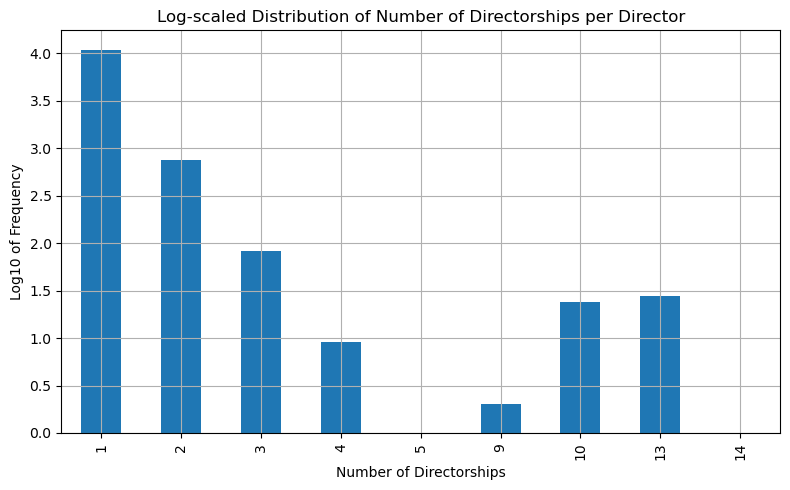

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
directorship_counts.value_counts().sort_index().map(math.log10).plot(kind='bar')
plt.title("Log-scaled Distribution of Number of Directorships per Director")
plt.xlabel("Number of Directorships")
plt.ylabel("Log10 of Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


### Fix 3: Renamed `graph` to `board_network`

The original variable name `graph` was too generic and unclear. Renaming it to `board_network` makes it more meaningful and helps indicate that this network specifically represents the connections between board members and companies.


In [15]:
import networkx as nx
board_network = nx.Graph() 

### Fix 4: Replaced list append with `.unique()`

The original code appended to a list inside a loop which was inefficient and risked duplication. Using `.unique()` is simpler, faster and guarantees clean non-redundant lists of people and companies.


In [17]:
for company_name, director_name in zip(df.company_name, df.director_name):
    board_network.add_edge(company_name, director_name)

people = df.director_name.unique().tolist()
companies = df.company_name.unique().tolist()

In [19]:
biggest_connected_graph = board_network.subgraph(list(nx.connected_components(board_network))[0])


## Task 1 : Centrality Extension

## Centrality Measures

- **Degree Centrality**: This shows how many direct connections a director has in other words how many boards they sit on. A director with high degree centrality may be useful because they’re likely to know many people and can easily spread information or opportunities across multiple companies.

- **Eigenvector Centrality**: This goes a step further it doesn’t just look at how many connections a director has but how connected their connections are. In this case, someone with high eigenvector centrality might be well-respected or highly influential because they’re embedded in an influential part of the network.

- **Betweenness Centrality**: This measures how often a director sits on the shortest path between other nodes. A director with high betweenness can act as a bridge between different groups of companies. They might be able to connect firms that don’t normally interact  which is ideal if we’re trying to get our company noticed by a big US based acquirer.


In [31]:
import networkx as nx

centrality = pandas.DataFrame({
    'eigen': pandas.Series(nx.eigenvector_centrality(biggest_connected_graph)),
    'degree': pandas.Series(nx.degree_centrality(biggest_connected_graph)),
    'betweenness': pandas.Series(nx.betweenness_centrality(biggest_connected_graph, k=100, seed=42))
})

In [37]:
centrality['is_person'] = centrality.index.map(lambda x: x in people)

people_df = centrality[centrality.is_person].merge(
    compensation_and_demographics,
    left_index=True,
    right_index=True
)

In [39]:
people_df.sort_values('eigen', ascending=False)

,eigen,degree,betweenness,is_person,age,compensation,gender,log_compensation
TERESA M. RESSEL,1.024389e-01,0.001585,0.000002,True,62,3190130,female,6.503809
DANIEL S. VANDIVORT,1.024389e-01,0.001585,0.000002,True,69,3353265,male,6.525468
JOEL W. MOTLEY,1.024389e-01,0.001585,0.000002,True,72,3118870,male,6.493997
PREMA MATHAI-DAVIS,1.024389e-01,0.001585,0.000002,True,74,3208265,female,6.506270
ELI JONES,1.024389e-01,0.001585,0.000002,True,63,3063255,male,6.486183
...,...,...,...,...,...,...,...,...
FRANCIS V. CUTTITA,8.400282e-35,0.000122,0.000000,True,56,145000,male,5.161371
ANDREW S. BORODACH,8.342633e-35,0.000122,0.000000,True,56,0,male,0.000000
LAWRENCE A. KOBRIN,8.342633e-35,0.000122,0.000000,True,91,30356,male,4.482259
NANCY J. FLOYD PRUE,8.342633e-35,0.000122,0.000000,True,70,50356,female,4.702060


In [41]:
df[df.director_name == 'ELIZABETH KRENTZMAN']

,company_name,cikcode,director_name,software_background,start_date,end_date
6297,Invesco Advantage Municipal Income Trust II,908993,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6352,Invesco Bond Fund,5094,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6407,Invesco California Value Municipal Income Trust,895531,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6462,Invesco High Income Trust II,846671,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6512,Invesco Municipal Income Opportunities Trust,835333,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6546,Invesco Municipal Opportunity Trust,884152,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6601,Invesco Municipal Trust,877463,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6656,Invesco Pennsylvania Value Municipal Income Trust,895528,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6706,Invesco Quality Municipal Income Trust,885125,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02
6740,Invesco Senior Income Trust,1059386,ELIZABETH KRENTZMAN,False,2021-06-22,2024-07-02


In [43]:
import sklearn.cluster

In [45]:
import sklearn.preprocessing
robust_scaler = sklearn.preprocessing.RobustScaler()
age_and_demographics_scaled = robust_scaler.fit_transform(people_df[['age', 'log_compensation', 'degree', 'eigen']])


In [47]:
dbscan = sklearn.cluster.DBSCAN(eps=0.4)
people_df['cluster_id'] = dbscan.fit_predict(age_and_demographics_scaled)
people_df.cluster_id.value_counts()

cluster_id
 1    3101
 0     384
 2     107
-1      72
 3      24
 4      19
 7       8
 6       5
 5       3
Name: count, dtype: int64

<Axes: xlabel='age', ylabel='log_compensation'>

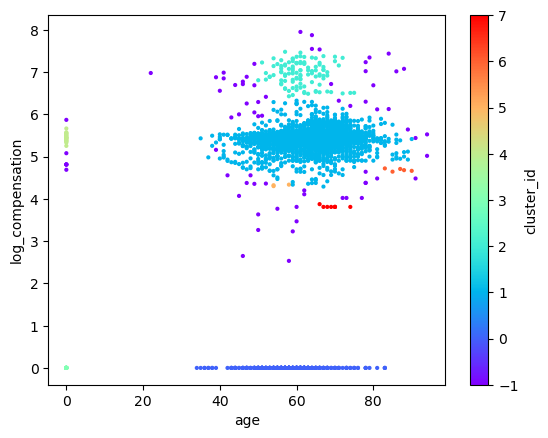

In [49]:
people_df.plot.scatter(x='age', y='log_compensation', c='cluster_id', cmap="rainbow", s=4)

In [71]:
people_df.loc['ELIZABETH KRENTZMAN']

eigen               0.102439
degree              0.001585
betweenness         0.000002
is_person               True
age                       65
compensation         3408245
gender                female
log_compensation    6.532531
cluster_id                 2
Name: ELIZABETH KRENTZMAN, dtype: object

## Task 3: Exploration of an Unused Feature



One variable that has not been utilized in the current analysis is `software_background` from the `company_directorships.csv` dataset. This binary feature identifies whether a director has a background in software or technology. Given the increasing role of digital innovation in corporate strategy and M&A activity, it could be valuable to investigate whether directors with a technical background hold more influential positions in the network. This insight could assist in identifying potential connectors to tech-driven acquirers or innovation-focused firms, aligning with the venture capital fund’s goal of facilitating an acquisition.

## Task 4: Complementary Dataset Proposal

I would use the [Forbes Global 2000(2023)](https://www.kaggle.com/datasets/ritika01mp/forbes-global-2000-2008-2023-mil-unit) dataset, which provides annual rankings of the world’s largest publicly traded companies. This dataset includes critical financial indicators like market cap, revenue and profit, and can help filter for large US firms that are likely to pursue acquisitions. By cross referencing industries or identifying overlapping board memberships, this dataset could support strategic targeting of influential directors who may facilitate a deal aligning with the venture fund's goal of accelerating an exit.

## Task 5b: Using the Forbes Global 2000 (2023) Dataset

To expand the analysis, I used the Forbes Global 2000 (2023) dataset, focusing on companies based in the United States. I filtered Forbes data and matched company names with the director-company network. This revealed a number of directors in our network who serve on boards of large, high-value public firms. 

These individuals may be strategically positioned to facilitate a potential acquisition and should be prioritized in follow-up efforts. This complements the VC fund's goal of exiting via a well-connected US acquirer.


In [98]:
import pandas as pd

# Loading Forbes dataset
forbes_df = pd.read_excel('Forbes Global 2000 - 2023  unified industry.xlsx')
forbes_df['Company_clean'] = forbes_df['Company'].str.upper().str.strip()

# Loading the network data
df = pd.read_csv('company_directorships.csv')
df['company_name_clean'] = df['company_name'].str.upper().str.strip()

# Filtering for US-based companies from Forbes
us_forbes = forbes_df[forbes_df['Country'] == 'United States']

# Matching companies from your network with Forbes US companies
matched_companies = df[df['company_name_clean'].isin(us_forbes['Company_clean'])]

# Previewing matched results
matched_companies[['company_name', 'director_name']].drop_duplicates().head(10)


,company_name,director_name
66,ABBOTT LABORATORIES,CLAIRE BABINEAUX- FONTENOT
67,ABBOTT LABORATORIES,CLAIRE BABINEAUX-FONTENOT
68,ABBOTT LABORATORIES,DANIEL J. STARKS
69,ABBOTT LABORATORIES,DARREN W. MCDEW
70,ABBOTT LABORATORIES,GLENN F. TILTON
71,ABBOTT LABORATORIES,JOHN G. STRATTON
72,ABBOTT LABORATORIES,MICHAEL F. ROMAN
73,ABBOTT LABORATORIES,MICHAEL G. O’GRADY
74,ABBOTT LABORATORIES,MICHELLE A. KUMBIER
75,ABBOTT LABORATORIES,NANCY MCKINSTRY


## Task 5c: Ethical Reflection

This project involves evaluating company directors based on centrality metrics derived from publicly available board membership data. While the dataset is legally accessible, there are important ethical considerations to acknowledge.

First, directors are ranked and analyzed without their explicit consent. Although the data is public, using it to measure influence and facilitate acquisition strategies may not align with how those individuals expect their information to be used.

Second, network centrality metrics offer a limited view. They highlight structural position but ignore qualitative aspects such as leadership skill, ethical behavior or boardroom performance. Over-reliance on these measures could lead to biased or incomplete decision-making.

Finally, transparency is crucial. If this analysis were shared with stakeholders or decision-makers they should be informed about how these insights were generated, their limitations and the ethical implications of acting on them.

Ethical data science involves more than technical correctness—it requires awareness of how insights affect people and a commitment to responsible use.


### Use of Generative AI

I used ChatGPT to support the development of this assignment by guiding the structure of the code, suggesting markdown explanations and drafting parts of the documentation. All outputs were critically reviewed, modified and verified to ensure originality and clarity.


## References

- Kaggle. (n.d.). *Forbes Global 2000 (2008–2023)* [Dataset]. Retrieved from [https://www.kaggle.com/datasets/ritika01mp/forbes-global-2000-2008-2023-mil-unit](https://www.kaggle.com/datasets/ritika01mp/forbes-global-2000-2008-2023-mil-unit)

- NetworkX Developers. (n.d.). *NetworkX: Network Analysis in Python*. Retrieved from [https://networkx.org/](https://networkx.org/)

- pandas Development Team. (n.d.). *pandas - Python Data Analysis Library*. Retrieved from [https://pandas.pydata.org/](https://pandas.pydata.org/)

- matplotlib Developers. (n.d.). *Matplotlib: Visualization with Python*. Retrieved from [https://matplotlib.org/](https://matplotlib.org/)

- scikit-learn Developers. (n.d.). *scikit-learn: Machine Learning in Python*. Retrieved from [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
